In [1]:
%pip install pandas numpy networkx matplotlib streamlit plotly

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Sarang\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


NETWORK TRAFFIC ANALYZER
Total records: 10
Unique devices: 8
Total packets: 2315
Total data transferred: 2493.16 KB

Protocol Distribution:
protocol
TCP     7
UDP     2
ICMP    1
Name: count, dtype: int64

Top Source IP Addresses:
source_ip
10.0.0.2    2360000
10.0.0.5      80000
10.0.0.6      45000
10.0.0.4      30000
10.0.0.3      25000
Name: bytes, dtype: int64

Top Destination IP Addresses:
destination_ip
10.0.0.8    2120000
10.0.0.5     353000
10.0.0.2      80000
Name: bytes, dtype: int64

Potentially Unusual Traffic:
source_ip destination_ip protocol  packets   bytes           timestamp
 10.0.0.2       10.0.0.8      TCP      800  950000 2026-10-19 09:03:00
 10.0.0.2       10.0.0.8      TCP      950 1100000 2026-10-19 09:06:00


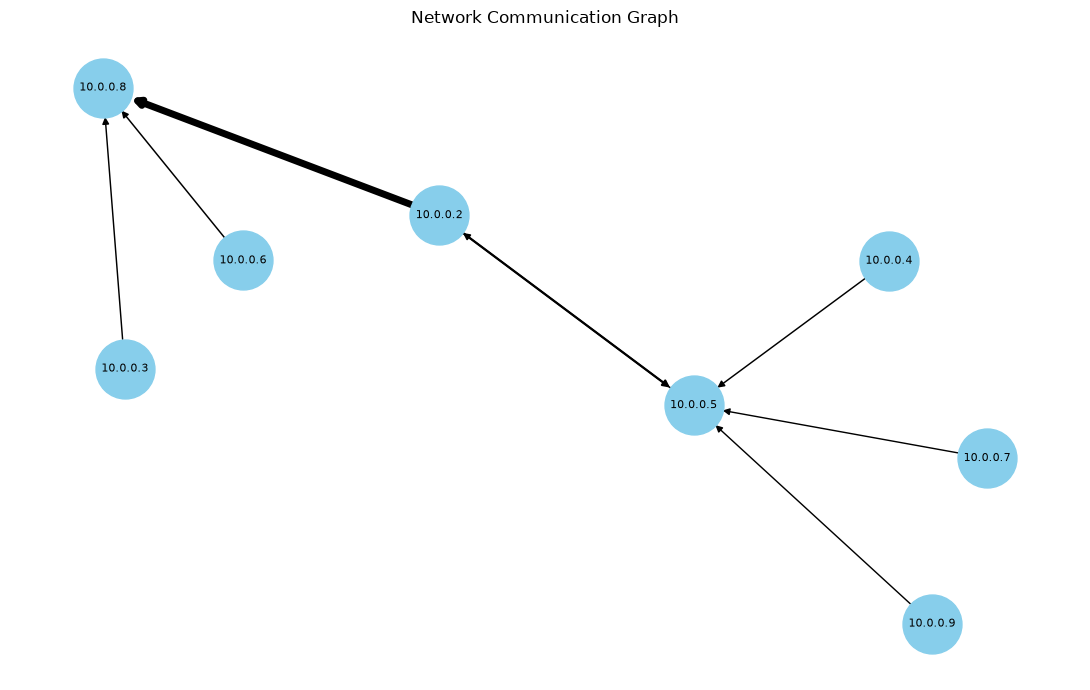

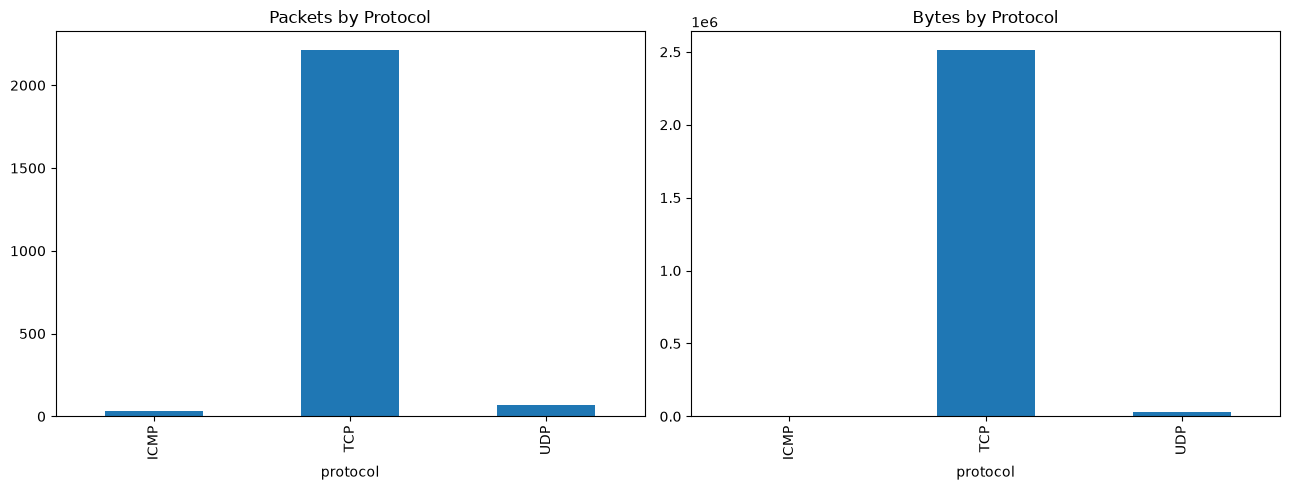

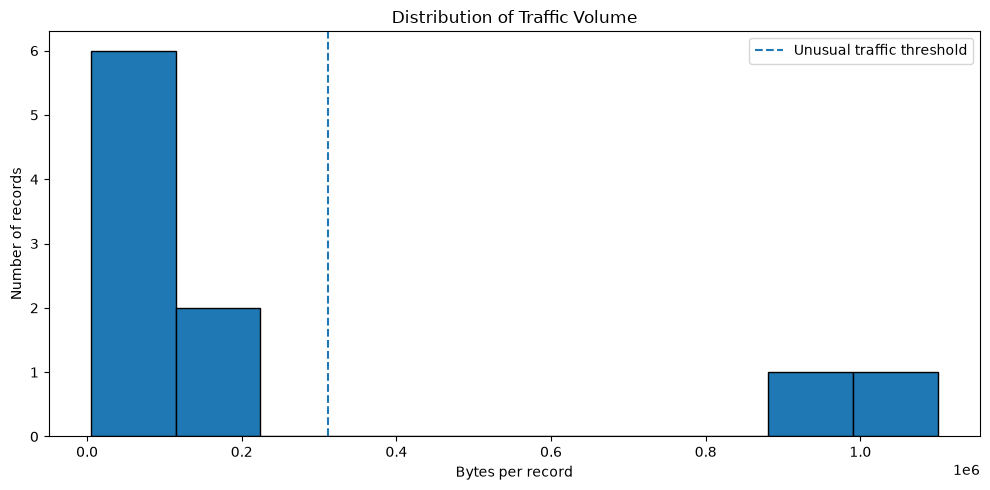


Analysis saved to analyzed_network_traffic.csv


In [4]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

df = pd.read_csv("analyzed_network_traffic.csv")

required = [
    "source_ip", "destination_ip", "protocol",
    "packets", "bytes", "timestamp"
]

if not all(col in df.columns for col in required):
    raise ValueError("Dataset is missing required columns")

df = df.dropna(subset=required).copy()
df["protocol"] = df["protocol"].astype(str).str.upper()
df["packets"] = pd.to_numeric(df["packets"], errors="coerce")
df["bytes"] = pd.to_numeric(df["bytes"], errors="coerce")
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.dropna(subset=["packets", "bytes", "timestamp"])
df = df[(df["packets"] >= 0) & (df["bytes"] >= 0)]

if df.empty:
    raise ValueError("No valid traffic records found")

print("NETWORK TRAFFIC ANALYZER")
print("=" * 40)
print("Total records:", len(df))
print("Unique devices:", len(set(df["source_ip"]) | set(df["destination_ip"])))
print("Total packets:", int(df["packets"].sum()))
print("Total data transferred:", round(df["bytes"].sum() / 1024, 2), "KB")

print("\nProtocol Distribution:")
print(df["protocol"].value_counts())

print("\nTop Source IP Addresses:")
print(df.groupby("source_ip")["bytes"].sum().nlargest(5))

print("\nTop Destination IP Addresses:")
print(df.groupby("destination_ip")["bytes"].sum().nlargest(5))

def anomaly_threshold(series):
    median = series.median()
    mad = (series - median).abs().median()

    if mad > 0:
        return median + 3 * 1.4826 * mad

    return series.quantile(0.95)

packet_limit = anomaly_threshold(df["packets"])
byte_limit = anomaly_threshold(df["bytes"])

df["anomaly"] = (
    (df["packets"] > packet_limit) |
    (df["bytes"] > byte_limit)
)

print("\nPotentially Unusual Traffic:")
alerts = df[df["anomaly"]]

if alerts.empty:
    print("No records crossed the configured thresholds.")
else:
    print(alerts[
        ["source_ip", "destination_ip", "protocol",
         "packets", "bytes", "timestamp"]
    ].to_string(index=False))

G = nx.DiGraph()

for _, row in df.iterrows():
    source = row["source_ip"]
    destination = row["destination_ip"]

    if G.has_edge(source, destination):
        G[source][destination]["bytes"] += row["bytes"]
        G[source][destination]["packets"] += row["packets"]
    else:
        G.add_edge(
            source,
            destination,
            bytes=row["bytes"],
            packets=row["packets"]
        )

plt.figure(figsize=(11, 7))

positions = nx.spring_layout(G, seed=42)
weights = [
    1 + 4 * G[u][v]["bytes"] / max(
        G[a][b]["bytes"] for a, b in G.edges()
    )
    for u, v in G.edges()
]

nx.draw_networkx(
    G,
    positions,
    node_color="skyblue",
    node_size=1800,
    font_size=8,
    arrows=True,
    width=weights
)

plt.title("Network Communication Graph")
plt.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df.groupby("protocol")["packets"].sum().plot(
    kind="bar", ax=axes[0], title="Packets by Protocol"
)

df.groupby("protocol")["bytes"].sum().plot(
    kind="bar", ax=axes[1], title="Bytes by Protocol"
)

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(df["bytes"], bins=min(10, len(df)), edgecolor="black")
plt.axvline(
    byte_limit,
    linestyle="--",
    label="Unusual traffic threshold"
)
plt.title("Distribution of Traffic Volume")
plt.xlabel("Bytes per record")
plt.ylabel("Number of records")
plt.legend()
plt.tight_layout()
plt.show()

df.to_csv("analyzed_network_traffic.csv", index=False)
print("\nAnalysis saved to analyzed_network_traffic.csv")